In [1]:
import numpy as np, pandas as pd
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
raw, proc = root / "data" / "raw", root / "data" / "processed"
proc.mkdir(exist_ok=True)

dfs = []
for f in sorted(raw.glob("*.csv")):
    d = pd.read_csv(f, low_memory=False)
    d.columns = d.columns.str.strip()
    fl = d.select_dtypes("float64").columns
    d[fl] = d[fl].astype("float32")
    d["source_file"] = f.name
    dfs.append(d)
    print(f.name, d.shape)

df = pd.concat(dfs, ignore_index=True)
del dfs
df["Label"] = (df["Label"].str.replace("\ufffd", "-", regex=False)
                          .str.replace("Web Attack - ", "Web Attack ", regex=False)
                          .str.strip())
df.to_parquet(proc / "all_raw.parquet")
print("OK", df.shape)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 80)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 80)
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 80)
Monday-WorkingHours.pcap_ISCX.csv (529918, 80)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 80)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 80)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 80)
Wednesday-workingHours.pcap_ISCX.csv (692703, 80)
OK (2830743, 80)


In [2]:
feat_cols = [c for c in df.columns if c != "source_file"]
num_cols = df.select_dtypes(include=np.number).columns

bad = np.zeros(len(df), dtype=bool)
for c in num_cols:
    bad |= ~np.isfinite(df[c].to_numpy())
print("Lignes inf/NaN :", bad.sum())

clean = df.loc[~bad].drop_duplicates(subset=feat_cols)
clean.to_parquet(proc / "clean.parquet")

report = pd.DataFrame({"avant": df["Label"].value_counts(),
                       "apres": clean["Label"].value_counts()})
report["perdu_%"] = ((1 - report["apres"] / report["avant"]) * 100).round(1)
print(report)
print(len(df), "->", len(clean))

Lignes inf/NaN : 2867
                            avant    apres  perdu_%
Label                                              
BENIGN                    2273097  2072444      8.8
Bot                          1966     1948      0.9
DDoS                       128027   128014      0.0
DoS GoldenEye               10293    10286      0.1
DoS Hulk                   231073   172846     25.2
DoS Slowhttptest             5499     5228      4.9
DoS slowloris                5796     5385      7.1
FTP-Patator                  7938     5931     25.3
Heartbleed                     11       11      0.0
Infiltration                   36       36      0.0
PortScan                   158930    90694     42.9
SSH-Patator                  5897     3219     45.4
Web Attack Brute Force       1507     1470      2.5
Web Attack Sql Injection       21       21      0.0
Web Attack XSS                652      652      0.0
2830743 -> 2498185


In [3]:
before = df["Label"].value_counts()

clean = (df.replace([np.inf, -np.inf], np.nan)
           .dropna()
           .drop_duplicates(subset=feat_cols))

after = clean["Label"].value_counts()

report = pd.DataFrame({"avant": before, "apres": after})
report["perdu_%"] = ((1 - report["apres"] / report["avant"]) * 100).round(1)
print(report)
print(len(df), "->", len(clean))

                            avant    apres  perdu_%
Label                                              
BENIGN                    2273097  2072444      8.8
Bot                          1966     1948      0.9
DDoS                       128027   128014      0.0
DoS GoldenEye               10293    10286      0.1
DoS Hulk                   231073   172846     25.2
DoS Slowhttptest             5499     5228      4.9
DoS slowloris                5796     5385      7.1
FTP-Patator                  7938     5931     25.3
Heartbleed                     11       11      0.0
Infiltration                   36       36      0.0
PortScan                   158930    90694     42.9
SSH-Patator                  5897     3219     45.4
Web Attack Brute Force       1507     1470      2.5
Web Attack Sql Injection       21       21      0.0
Web Attack XSS                652      652      0.0
2830743 -> 2498185


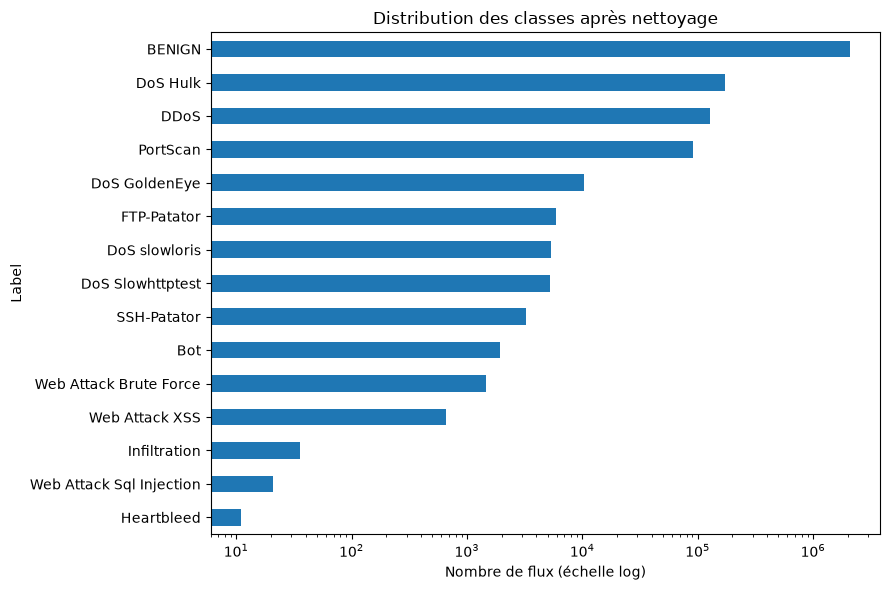

In [4]:
import matplotlib.pyplot as plt

ax = clean["Label"].value_counts().plot(kind="barh", figsize=(9, 6), logx=True)
ax.set_xlabel("Nombre de flux (échelle log)")
ax.set_title("Distribution des classes après nettoyage")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
import numpy as np, pandas as pd
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
clean = pd.read_parquet(root / "data" / "processed" / "clean.parquet")

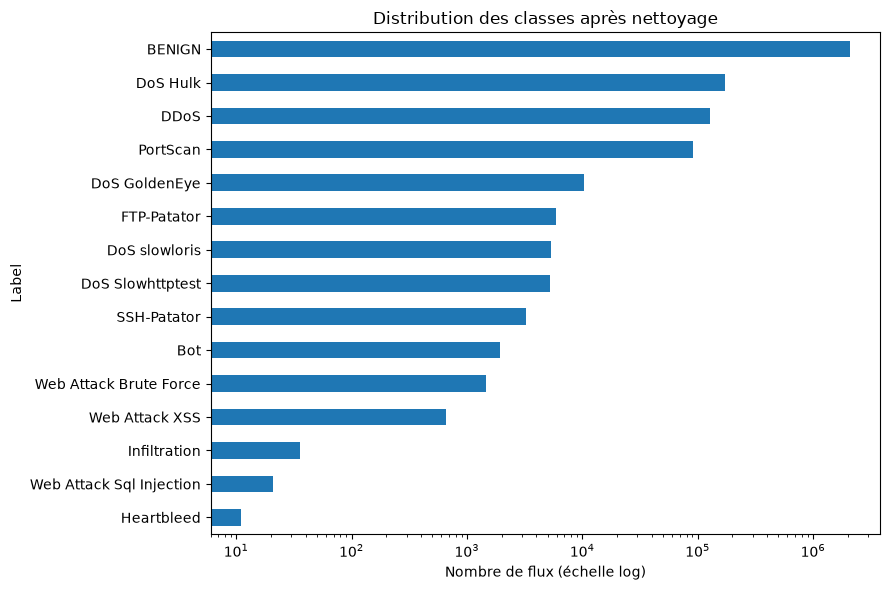

In [6]:
import matplotlib.pyplot as plt

ax = clean["Label"].value_counts().plot(kind="barh", figsize=(9, 6), logx=True)
ax.set_xlabel("Nombre de flux (échelle log)")
ax.set_title("Distribution des classes après nettoyage")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

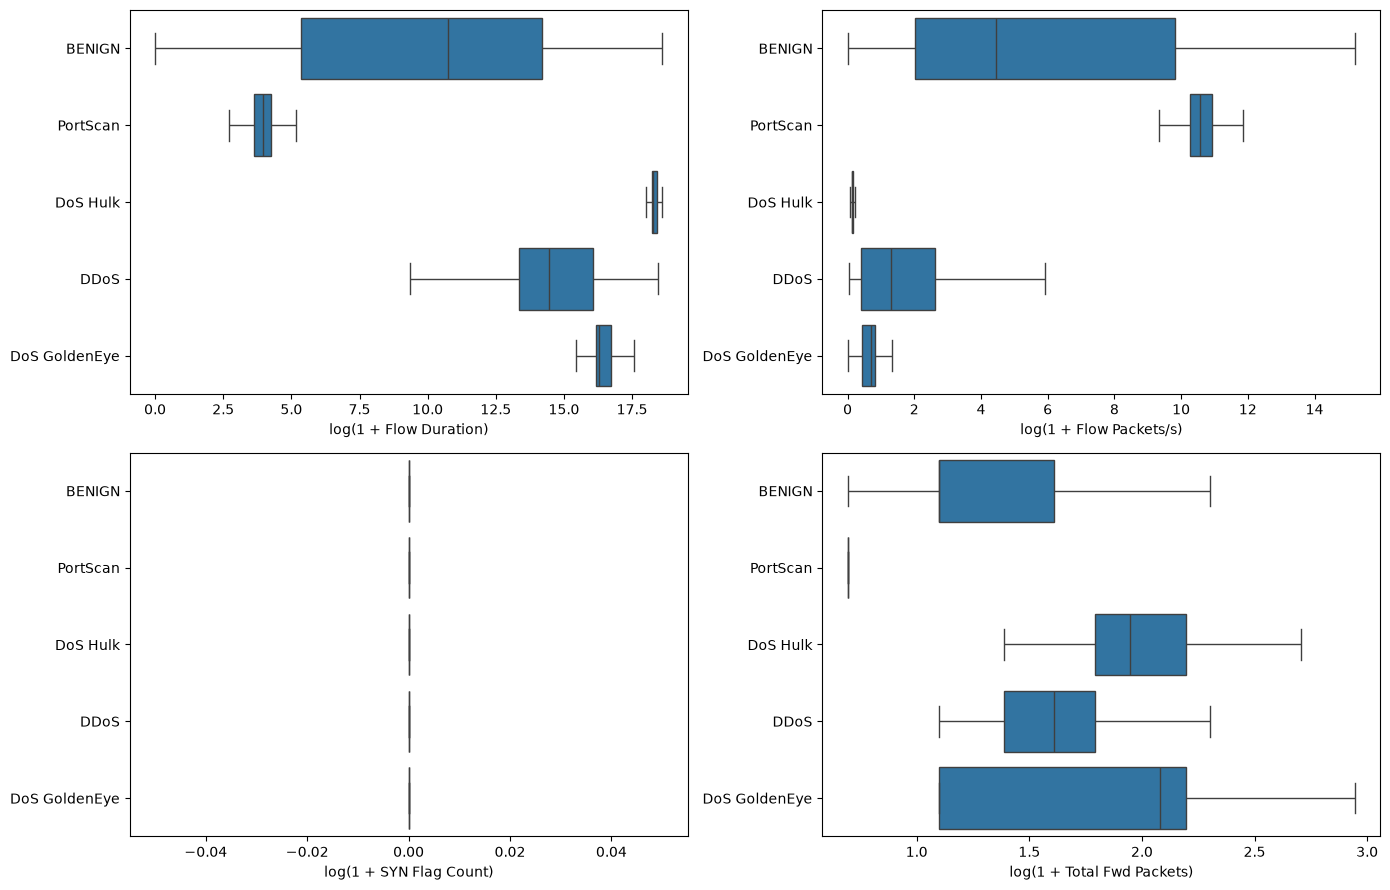

In [7]:
import seaborn as sns

feats = ["Flow Duration", "Flow Packets/s", "SYN Flag Count", "Total Fwd Packets"]
top = clean["Label"].value_counts().index[:5]          # BENIGN + 4 classes les plus fréquentes
sample = clean[clean["Label"].isin(top)].sample(100_000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, f in zip(axes.ravel(), feats):
    sns.boxplot(data=sample, y="Label", x=np.log1p(sample[f].clip(lower=0)), ax=ax, showfliers=False)
    ax.set_xlabel(f"log(1 + {f})")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

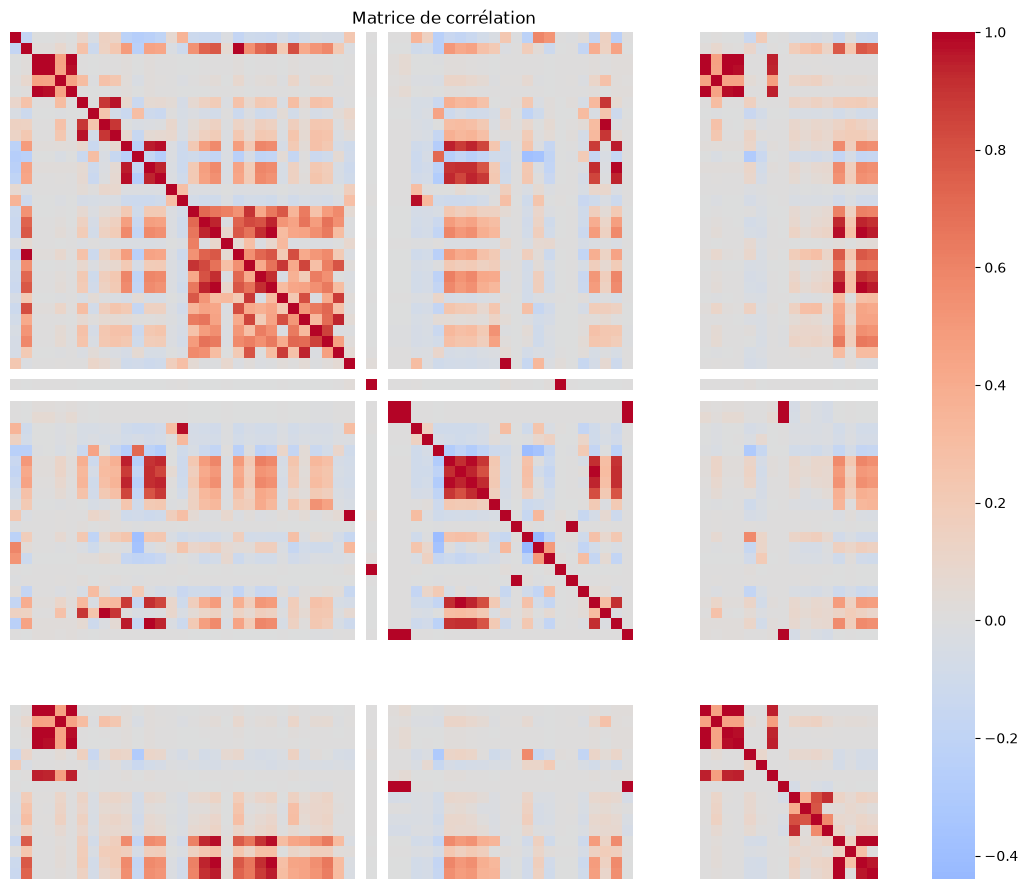

44 paires > 0,95
Total Fwd Packets            Subflow Fwd Packets     1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes       1.000000
Total Backward Packets       Subflow Bwd Packets     1.000000
Fwd Packet Length Mean       Avg Fwd Segment Size    1.000000
Fwd URG Flags                CWE Flag Count          1.000000
Fwd PSH Flags                SYN Flag Count          1.000000
Bwd Packet Length Mean       Avg Bwd Segment Size    1.000000
Fwd Header Length            Fwd Header Length.1     1.000000
Total Length of Bwd Packets  Subflow Bwd Bytes       1.000000
Fwd Header Length.1          min_seg_size_forward    0.999715
Fwd Header Length            min_seg_size_forward    0.999715
Bwd Header Length            Fwd Header Length.1     0.999417
Fwd Header Length            Bwd Header Length       0.999417
Flow Duration                Fwd IAT Total           0.998565
Bwd Header Length            min_seg_size_forward    0.998322
dtype: float64


In [8]:
sample2 = clean.select_dtypes(include=np.number).sample(200_000, random_state=42)
corr = sample2.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Matrice de corrélation")
plt.show()

# Paires très corrélées (> 0,95)
pairs = (corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().loc[lambda s: s > 0.95].sort_values(ascending=False))
print(len(pairs), "paires > 0,95")
print(pairs.head(15))